# Week 1 Assessment - Employee Data Analysis

This notebook covers Task 3 (NumPy, Pandas, Matplotlib) step by step.
It reads the original `task3_numpy_pandas/data/employees.csv` and `departments.csv` and never changes them.
Tasks 1, 2 and 3 are in the `task1_python_oop/`, `task2_files_api/` and `task3_numpy_pandas/` folders.

## 1. Setup
Import the libraries and find the project folder, so the notebook works
whether Jupyter starts in `task4_notebook_git/` or in the project root.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "task4_notebook_git" else Path.cwd()
DATA = ROOT / "task3_numpy_pandas" / "data"
print("Project folder:", ROOT.name)

Project folder: week1-assessment


## 2. NumPy - student marks
A 4 x 3 array: 4 students (rows) and 3 subjects (columns: Maths, Science, English).
- `axis=1` works across a row, which gives one average per **student**.
- `axis=0` works down a column, which gives one average per **subject**.

In [2]:
students = ["Asha", "Bala", "Chitra", "Dinesh"]
subjects = ["Maths", "Science", "English"]
marks = np.array([[78, 85, 90],
                  [65, 70, 72],
                  [88, 92, 80],
                  [55, 60, 68]])

print("Shape:", marks.shape)
print("Student averages (axis=1):", marks.mean(axis=1).round(2))
print("Subject averages (axis=0):", marks.mean(axis=0).round(2))

Shape: (4, 3)
Student averages (axis=1): [84.33 69.   86.67 61.  ]
Subject averages (axis=0): [71.5  76.75 77.5 ]


**Broadcasting:** adding the single number 5 to the whole array adds 5 grace marks to every cell.
**np.dot:** multiplies each student's marks by the subject weights and adds them up.

In [3]:
print("After 5 grace marks:")
print(marks + 5)

weights = np.array([0.4, 0.35, 0.25])   # Maths 40%, Science 35%, English 25%
print("Weighted scores:", np.dot(marks, weights).round(2))

After 5 grace marks:
[[83 90 95]
 [70 75 77]
 [93 97 85]
 [60 65 73]]
Weighted scores: [83.45 68.5  87.4  60.  ]


### Timing with %timeit
`%timeit` runs a line many times and reports how long it takes on average.

In [4]:
%timeit marks.mean(axis=1)

2.65 μs ± 213 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


## 3. Pandas - load and explore employees
`info()` shows the columns, data types and missing values.
`describe()` shows count, mean, min and max for the number columns.

In [5]:
df = pd.read_csv(DATA / "employees.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          8 non-null      int64
 1   name        8 non-null      str  
 2   department  8 non-null      str  
 3   salary      8 non-null      int64
 4   city        8 non-null      str  
dtypes: int64(2), str(3)
memory usage: 452.0 bytes


In [6]:
df.describe()

,id,salary
count,8.00000,8.000000
mean,4.50000,58500.000000
std,2.44949,18913.336187
min,1.00000,30000.000000
25%,2.75000,47250.000000
50%,4.50000,56000.000000
75%,6.25000,69750.000000
max,8.00000,90000.000000


- `loc` selects by **label** (row condition + column names).
- `iloc` selects by **position** (row and column numbers).
- A boolean filter keeps only rows where the condition is True.

In [7]:
print("loc - Chennai employees:")
print(df.loc[df["city"] == "Chennai", ["name", "salary"]])

print("\niloc - first 3 rows, first 3 columns:")
print(df.iloc[0:3, 0:3])

print("\nFilter - salary above 50000:")
print(df[df["salary"] > 50000])

loc - Chennai employees:
     name  salary
0    Arun   30000
1   Priya   45000
3   Divya   75000
6  Suresh   68000

iloc - first 3 rows, first 3 columns:
   id   name department
0   1   Arun      Sales
1   2  Priya         HR
2   3  Rahul         IT

Filter - salary above 50000:
   id     name department  salary       city
2   3    Rahul         IT   60000  Bangalore
3   4    Divya         IT   75000    Chennai
4   5  Karthik    Finance   90000     Mumbai
5   6    Meena      Sales   52000  Bangalore
6   7   Suresh         IT   68000    Chennai


## 4. Cleaning a working copy
To practise cleaning without touching the real data, I make a messy **copy**:
two blank salaries (Priya, Meena), Rahul's row repeated, a salary stored as text,
and some text with extra spaces or the wrong case.

In [8]:
dirty = df.copy()
dirty["salary"] = dirty["salary"].astype(object)
dirty.loc[dirty["name"] == "Priya", "salary"] = None
dirty.loc[dirty["name"] == "Meena", "salary"] = None
dirty.loc[dirty["name"] == "Arun", "salary"] = "30000"
dirty.loc[dirty["name"] == "Arun", "city"] = "  chennai "
dirty.loc[dirty["name"] == "Meena", "department"] = "sales"
dirty.loc[dirty["name"] == "Anitha", "department"] = " hr "
dirty = pd.concat([dirty, dirty[dirty["name"] == "Rahul"]], ignore_index=True)

print("Rows:", len(dirty), "| Missing salaries:", dirty["salary"].isna().sum(),
      "| Duplicates:", dirty.duplicated().sum())
dirty

Rows: 9 | Missing salaries: 2 | Duplicates: 1


,id,name,department,salary,city
0,1,Arun,Sales,30000,chennai
1,2,Priya,HR,None,Chennai
2,3,Rahul,IT,60000,Bangalore
3,4,Divya,IT,75000,Chennai
4,5,Karthik,Finance,90000,Mumbai
5,6,Meena,sales,None,Bangalore
6,7,Suresh,IT,68000,Chennai
7,8,Anitha,hr,48000,Mumbai
8,3,Rahul,IT,60000,Bangalore


Cleaning steps:
1. **Standardise text** - strip spaces and fix case. `HR` and `IT` are short forms, so they stay in capitals.
2. **Remove duplicates** first, so the repeated row does not affect the median.
3. **Correct types** - turn the salary column into numbers.
4. **Fill missing salaries with the median** (not pulled up or down by extreme values like the mean is).

In [9]:
def standard_department(name):
    name = name.strip()
    if name.upper() in ["HR", "IT"]:
        return name.upper()
    return name.title()

clean = dirty.copy()
clean["name"] = clean["name"].str.strip().str.title()
clean["city"] = clean["city"].str.strip().str.title()
clean["department"] = clean["department"].apply(standard_department)
clean = clean.drop_duplicates()
clean["salary"] = pd.to_numeric(clean["salary"])
median_salary = clean["salary"].median()
clean["salary"] = clean["salary"].fillna(median_salary).astype(int)

print("Median used:", median_salary)
print("Rows:", len(clean), "| Missing salaries:", clean["salary"].isna().sum())
print("Departments:", sorted(clean["department"].unique()))
print("Headcount:", clean["department"].value_counts().to_dict())
print("Original unchanged:", df.equals(pd.read_csv(DATA / "employees.csv")))
clean.dtypes

Median used: 64000.0
Rows: 8 | Missing salaries: 0
Departments: ['Finance', 'HR', 'IT', 'Sales']
Headcount: {'IT': 3, 'Sales': 2, 'HR': 2, 'Finance': 1}
Original unchanged: True


id            int64
name            str
department      str
salary        int64
city            str
dtype: object

The cleaned copy has the same 8 employees and the same headcount as the original.
The rest of the analysis uses the **original** data, because the two filled salaries are only estimates.

## 5. Group by department
`groupby().agg()` gives headcount, average salary and maximum salary for each department.

In [10]:
summary = (df.groupby("department")
             .agg(headcount=("id", "count"),
                  avg_salary=("salary", "mean"),
                  max_salary=("salary", "max"))
             .reindex(["Sales", "HR", "IT", "Finance"]))
print("Headcount: " + " | ".join(f"{d} {n}" for d, n in summary["headcount"].items()))
summary.round(0)

Headcount: Sales 2 | HR 2 | IT 3 | Finance 1


,headcount,avg_salary,max_salary
department,,,
Sales,2,41000.0,52000
HR,2,46500.0,48000
IT,3,67667.0,75000
Finance,1,90000.0,90000


## 6. Merge with departments
- **inner** keeps only departments found in both tables (8 rows).
- **left** (departments on the left) keeps every department, even one with no employees (9 rows).
- **outer** keeps everything from both sides (9 rows).

The department whose employee columns are empty (NaN) after the outer merge has no employees.

In [11]:
departments = pd.read_csv(DATA / "departments.csv")
inner = pd.merge(df, departments, on="department", how="inner")
left = pd.merge(departments, df, on="department", how="left")
outer = pd.merge(df, departments, on="department", how="outer")
print("Inner:", len(inner), "| Left:", len(left), "| Outer:", len(outer))
print("No employees:", outer.loc[outer["id"].isna(), "department"].tolist())
outer[["department", "name", "salary", "head", "budget"]]

Inner: 8 | Left: 9 | Outer: 9
No employees: ['Marketing']


,department,name,salary,head,budget
0,Finance,Karthik,90000.0,Deepa,600000
1,HR,Priya,45000.0,Lakshmi,300000
2,HR,Anitha,48000.0,Lakshmi,300000
3,IT,Rahul,60000.0,Vijay,900000
4,IT,Divya,75000.0,Vijay,900000
5,IT,Suresh,68000.0,Vijay,900000
6,Marketing,NaN,NaN,Sanjay,400000
7,Sales,Arun,30000.0,Ramesh,500000
8,Sales,Meena,52000.0,Ramesh,500000


## 7. Charts
The same four charts are saved as PNG files in `task3_numpy_pandas/reports/charts/` by `task3.py`.

### 7.1 Bar chart - average salary by department

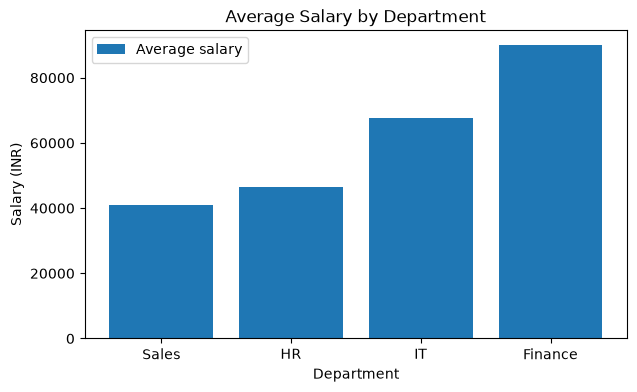

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(summary.index, summary["avg_salary"], label="Average salary")
ax.set_title("Average Salary by Department")
ax.set_xlabel("Department")
ax.set_ylabel("Salary (INR)")
ax.legend()
plt.show()

**Insight:** Finance has the highest average salary (90000 INR) and Sales the lowest (41000 INR).

### 7.2 Histogram - salary distribution

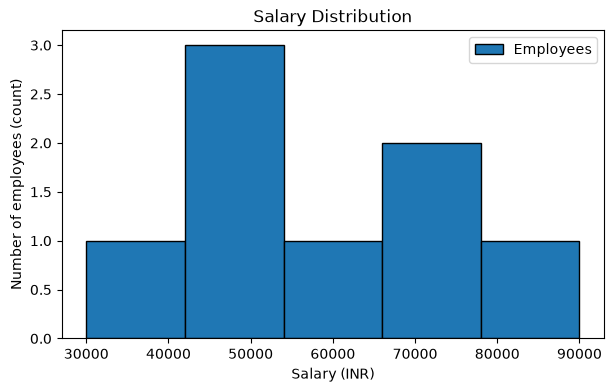

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df["salary"], bins=5, edgecolor="black", label="Employees")
ax.set_title("Salary Distribution")
ax.set_xlabel("Salary (INR)")
ax.set_ylabel("Number of employees (count)")
ax.legend()
plt.show()

**Insight:** The most common salary range is 42000-54000 INR, with 3 of the 8 employees.

### 7.3 Scatter plot - salary of each employee by city

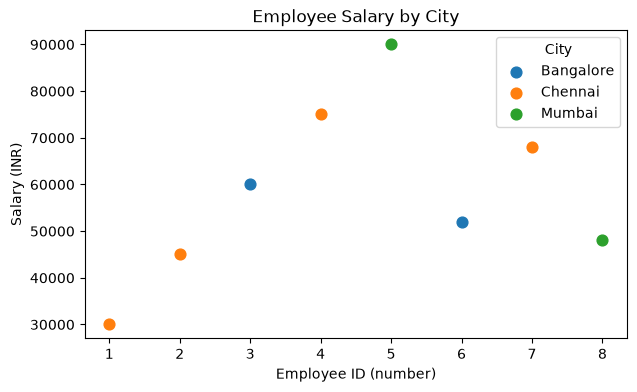

city
Bangalore    56000.0
Chennai      54500.0
Mumbai       69000.0
Name: salary, dtype: float64


In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
for city, group in df.groupby("city"):
    ax.scatter(group["id"], group["salary"], label=city, s=60)
ax.set_title("Employee Salary by City")
ax.set_xlabel("Employee ID (number)")
ax.set_ylabel("Salary (INR)")
ax.legend(title="City")
plt.show()
print(df.groupby("city")["salary"].mean())

**Insight:** Mumbai has the highest average salary by city (69000 INR).

### 7.4 Line chart - student marks by subject

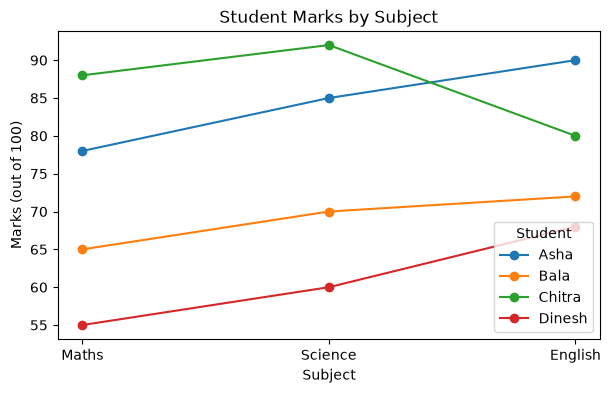

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, row in zip(students, marks):
    ax.plot(subjects, row, marker="o", label=name)
ax.set_title("Student Marks by Subject")
ax.set_xlabel("Subject")
ax.set_ylabel("Marks (out of 100)")
ax.legend(title="Student")
plt.show()

**Insight:** Chitra has the best average mark (86.67) and Dinesh the lowest (61.00).

## 8. Summary
1. Headcount: Sales 2 | HR 2 | IT 3 | Finance 1. Marketing has no employees.
2. Finance has the highest average salary (90000) and Sales the lowest (41000).
3. 5 of 8 employees earn above 50000; the most common salary range is 42000-54000.
4. Mumbai has the highest average salary by city (69000).
5. Chitra has the best average mark (86.67) and Dinesh the lowest (61.00).